## Setup

In [13]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
# import matplotlib.animation as anim
# import numpy as np
# from IPython.display import HTML

In [14]:
# run_name = "test_bins_more_decision_interval"
run_name = "test_bins_more_decision_interval_2"

comparison_run_name = "test_bins_more_decision_interval_100000_eps" # None

In [15]:
run_path = Path("../training_runs") / run_name
stats_path = run_path / "stats.json"

if comparison_run_name is not None:
    comparison_run_path = Path("../training_runs") / comparison_run_name
    comparison_stats_path = comparison_run_path / "stats.json"
    

In [16]:
with open(stats_path) as f:
    stats = json.load(f)

if comparison_run_name is not None:
    with open(comparison_stats_path) as f:
        comparison_stats = json.load(f)
    

In [17]:
n_episodes = stats["n_episodes"]
episode_stats = stats["episode_stats"]

rewards = [ep["rewards"] for ep in episode_stats]
if rewards[0] is None:
    rewards = None
    
rewards_sum_per_episode = [ep["rewards_sum"] for ep in episode_stats]

episode_states: list[list[dict[str, float]]] | None = [ep["states"] for ep in episode_stats]
if episode_states[0] is None:
    episode_states = None

if episode_states is not None:
    states_list: list[list[list[float]]] | None = [[list(state.values()) for state in states] for states in episode_states]
else:
    states_list = None
    
del episode_states

if comparison_run_name is not None:
    comparison_n_episodes = comparison_stats["n_episodes"]
    comparison_episode_stats = comparison_stats["episode_stats"]

    comparison_rewards = [ep["rewards"] for ep in comparison_episode_stats]
    if comparison_rewards[0] is None:
        comparison_rewards = None
    
    comparison_rewards_sum_per_episode = [ep['rewards_sum'] for ep in comparison_episode_stats]
    
    comparison_episode_states: list[list[dict[str, float]]] | None = [ep["states"] for ep in comparison_episode_stats]
    if comparison_episode_states[0] is None:
        comparison_episode_states = None
    if comparison_episode_states is not None:
        comparison_states_list: list[list[list[float]]] | None = [[list(state.values()) for state in states] for states in comparison_episode_states]
    else:
        comparison_states_list = None
    del comparison_episode_states
    

## episode end state over training time (FAIL vs time exceeded)

In [18]:
x = list(range(1, n_episodes+1))
failed_y = [1 if episode_stats[0]['end_state'] == "FAIL" else 0]

for i, ep in enumerate(episode_stats[1:], 1):
    failed_y.append(1 if episode_stats[i]['end_state'] == "FAIL" else 0)
    failed_y[i] += failed_y[i-1]
    
exceeded_y = [1 if episode_stats[0]['end_state'] == "STEPS_EXCEEDED" else 0]

for i, ep in enumerate(episode_stats[1:], 1):
    exceeded_y.append(1 if episode_stats[i]['end_state'] == "STEPS_EXCEEDED" else 0)
    exceeded_y[i] += exceeded_y[i-1]

if comparison_run_name is not None:
    comparison_x = list(range(1, comparison_n_episodes+1))
    comparison_failed_y = [1 if comparison_episode_stats[0]['end_state'] == "FAIL" else 0]

    for i, ep in enumerate(comparison_episode_stats[1:], 1):
        comparison_failed_y.append(1 if comparison_episode_stats[i]['end_state'] == "FAIL" else 0)
        comparison_failed_y[i] += comparison_failed_y[i-1]
        
    comparison_exceeded_y = [1 if comparison_episode_stats[0]['end_state'] == "STEPS_EXCEEDED" else 0]

    for i, ep in enumerate(comparison_episode_stats[1:], 1):
        comparison_exceeded_y.append(1 if comparison_episode_stats[i]['end_state'] == "STEPS_EXCEEDED" else 0)
        comparison_exceeded_y[i] += comparison_exceeded_y[i-1]
    

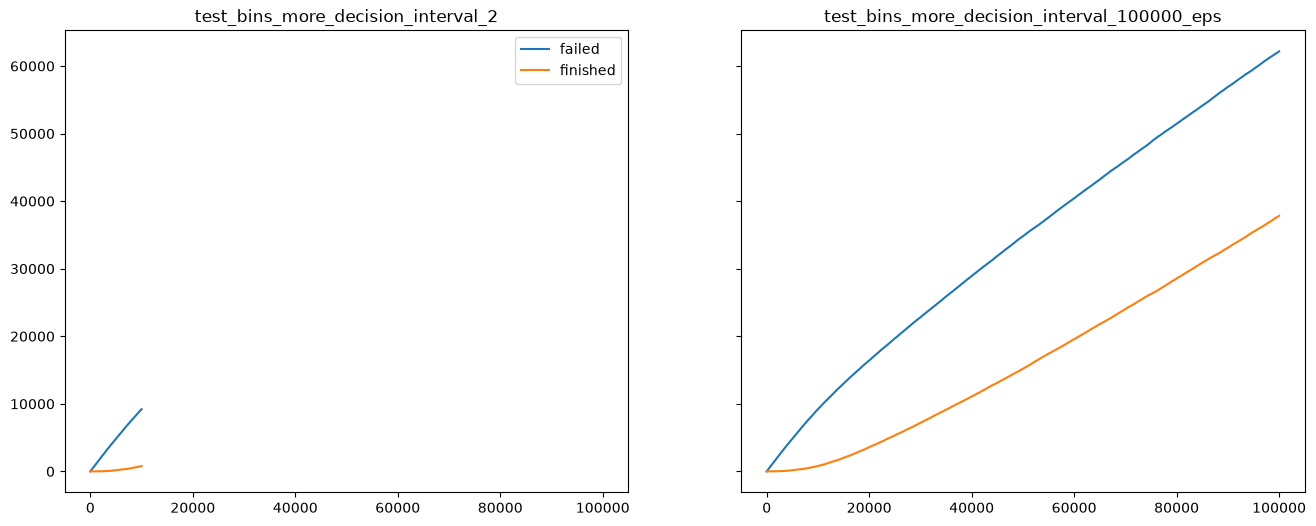

In [19]:
if comparison_run_name is None:
    fig, ax = plt.subplots(ncols=1, figsize=(8, 6))

    ax.plot(x, failed_y, label="failed")
    ax.plot(x, exceeded_y, label="finished")
    ax.set_title(f"{run_name}")
    ax.legend()

if comparison_run_name is not None:
    
    fig, ax = plt.subplots(ncols=2, figsize=(16, 6), sharey=True, sharex=True)

    ax[0].plot(x, failed_y, label="failed")
    ax[0].plot(x, exceeded_y, label="finished")
    ax[0].set_title(f"{run_name}")

    ax[1].plot(comparison_x, comparison_failed_y, label="failed")
    ax[1].plot(comparison_x, comparison_exceeded_y, label="finished")
    ax[1].set_title(f"{comparison_run_name}")

    ax[0].legend()

## reward over episode steps over episodes (dynamic)

In [20]:
if rewards is not None:

    x_max = max([ep["steps"] for ep in episode_stats])

    rewards_padded = [r + [None] * (x_max - len(r)) for r in rewards]
    x = list(range(1, x_max+1))
else:
    print("Skipped: episode: rewards per step per episode unsaved (--only-sums)")

Skipped: episode: rewards per step per episode unsaved (--only-sums)


In [21]:
if rewards is None:
    print("Skipped: rewards per step per episode unsaved (--only-sums)")
else:

    import plotly.graph_objects as go


    flat_rewards = [val for frame in rewards for val in frame]
    y_min = min(flat_rewards)
    y_max = max(flat_rewards)

    padding = (y_max - y_min) * 0.05 if y_max != y_min else 1.0
    y_range = [y_min - padding, y_max + padding]

    # Create a figure with Plotly frames
    fig = go.Figure(
        data=[go.Scatter(x=list(range(len(rewards_padded[0]))), y=rewards_padded[0], mode="lines")]
    )

    skip = 10

    # Build frames efficiently
    frames = [
        go.Frame(
            data=[go.Scatter(y=rewards_padded[t])],
            name=str(t),
            layout=dict(title=f"Time step: {t}"),
        )
        for t in range(0, n_episodes, skip)
    ]  # Optional: step by 10 for speed

    fig.frames = frames

    # Add play/pause buttons and slider
    fig.update_layout(
        yaxis=dict(
            range=y_range
        ),
        updatemenus=[{
            "type": "buttons",
            "buttons": [{
                "label": "Play",
                "method": "animate",
                "args": [
                    None,
                    {
                        "frame": {"duration": 25, "redraw": True},
                        'transition': {'duration': 0, 'easing': 'linear'},
                        "fromcurrent": True,
                    },
                ],
            }],
        }],
        sliders=[{
            "steps": [{
                "args": [
                    [str(t)],
                    {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"},
                ],
                "label": str(t),
                "method": "animate",
            } for t in range(0, n_episodes, skip)]
        }],
    )

    fig.show()

Skipped: rewards per step per episode unsaved (--only-sums)


## Last episode reward over training

In [22]:
if rewards is None:
    print("Skipped: rewards per step per episode unsaved (--only-sums)")
else:
    episode_last_rewards = [reward[-1] for reward in rewards]


    window_width =  251
    pad = window_width //2

    episode_last_rewards_p = np.pad(episode_last_rewards, pad, mode="edge")
    roll_last_rewards = sliding_window_view(episode_last_rewards_p, window_width).mean(axis=1)

    plt.plot(roll_last_rewards)

Skipped: rewards per step per episode unsaved (--only-sums)


## Episode reward sum over training

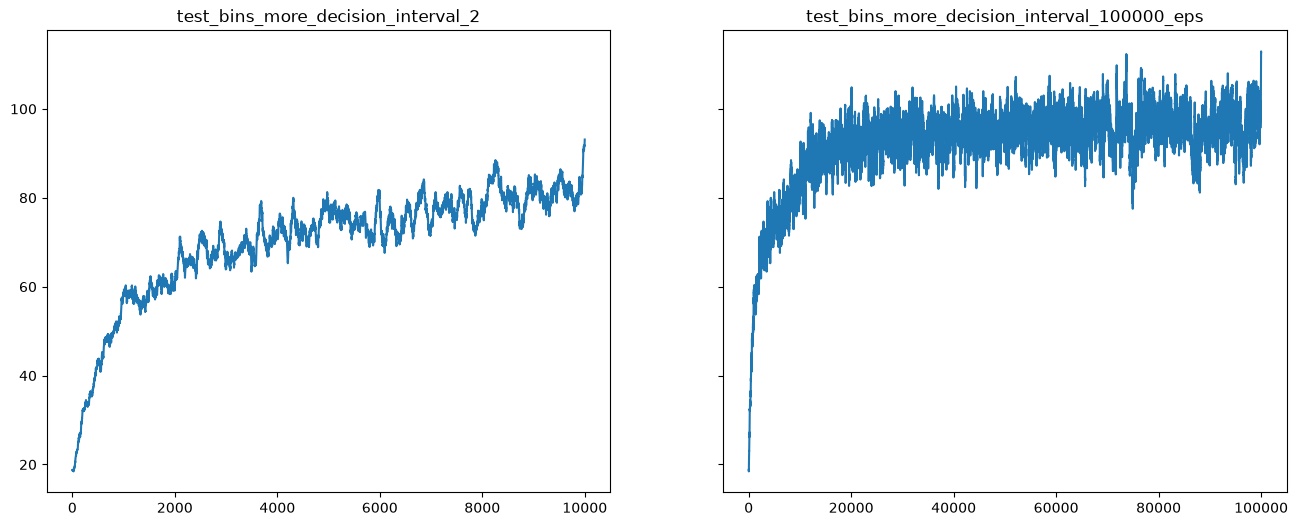

In [23]:
window_width =  101
pad = window_width //2

rewards_sum_per_episode_p = np.pad(rewards_sum_per_episode, pad, mode="edge")
roll_rewards_sum = sliding_window_view(rewards_sum_per_episode_p, window_width).mean(axis=1)

if comparison_run_name is None:
    plt.plot(roll_rewards_sum)
    
else:

    comparison_window_width =  window_width
    comparison_pad = comparison_window_width //2

    comparison_rewards_sum_per_episode_p = np.pad(comparison_rewards_sum_per_episode, comparison_pad, mode="edge")
    comparison_roll_rewards_sum = sliding_window_view(comparison_rewards_sum_per_episode_p, comparison_window_width).mean(axis=1)
    
    fig, ax = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)
    
    ax[0].plot(roll_rewards_sum)
    ax[0].set_title(f"{run_name}")
    ax[1].plot(comparison_roll_rewards_sum)
    ax[1].set_title(f"{comparison_run_name}")

# plt.plot(episode_rewards_sum)

## episode rewards average over training

In [24]:
if rewards is None:
    print("Skipped: rewards per step per episode unsaved (--only-sums)")
else:
    episode_rewards_avg = [np.mean(reward) for reward in rewards]


    window_width =  51
    pad = window_width //2

    episode_rewards_avg_p = np.pad(episode_rewards_avg, pad, mode="edge")
    roll_rewards_avg = sliding_window_view(episode_rewards_avg_p, window_width).mean(axis=1)

    plt.plot(roll_rewards_avg)
    # plt.plot(episode_rewards_sum)

Skipped: rewards per step per episode unsaved (--only-sums)


## max/min state values

In [25]:
if states_list is None:
    print("Skipped: states per step per episode unsaved (--no-states)")
else:
    mins = np.min([np.min(s, axis=0) for s in states_list], axis=0)
    maxs = np.max([np.max(s, axis=0) for s in states_list], axis=0)

    np.set_printoptions(precision=10, suppress=True)

    print(mins)
    print(maxs)

Skipped: states per step per episode unsaved (--no-states)
